Epoch 1/20, Loss: 0.8512995364069939
Epoch 2/20, Loss: 0.819453592658043
Epoch 3/20, Loss: 0.8085648022890091
Epoch 4/20, Loss: 0.801440390765667
Epoch 5/20, Loss: 0.7966834468841553
Epoch 6/20, Loss: 0.7928532656431199
Epoch 7/20, Loss: 0.7897566608786583
Epoch 8/20, Loss: 0.7871043663620949
Epoch 9/20, Loss: 0.7847598235011101
Epoch 10/20, Loss: 0.7828289005756378
Epoch 11/20, Loss: 0.7811009750962258
Epoch 12/20, Loss: 0.7796668984889984
Epoch 13/20, Loss: 0.778338773727417
Epoch 14/20, Loss: 0.7771049492359161
Epoch 15/20, Loss: 0.7759913359880447
Epoch 16/20, Loss: 0.7751432859301567
Epoch 17/20, Loss: 0.7743854600191117
Epoch 18/20, Loss: 0.7736183441877366
Epoch 19/20, Loss: 0.772964959025383
Epoch 20/20, Loss: 0.7722939408421516


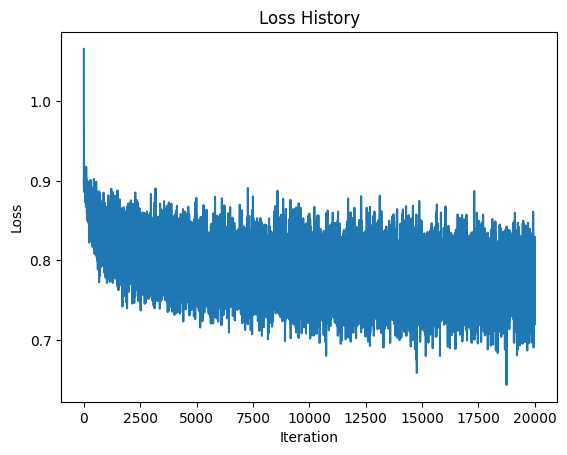

Training accuracy: 41.90%
Test accuracy: 40.94%


In [ ]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# 1. Data loading
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 50
trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)
testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck')

# 2. Network parameters
Din = 3 * 32 * 32
H = 100
K = 10
std = 1e-2

w1 = torch.randn(Din, H) * std
b1 = torch.zeros(H)
w2 = torch.randn(H, K) * std
b2 = torch.zeros(K)

# Hyperparameters
iterations = 20
lr = 1e-2
lr_decay = 0.9
reg = 0

loss_history = []


def sigmoid(z):
    return 1.0 / (1.0 + torch.exp(-z))


def forward(x):
    h = sigmoid(x.mm(w1) + b1)
    y = h.mm(w2) + b2
    return h, y


# 3. Training loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        h, y_pred = forward(x_train)

        # Loss: MSE + L2 regularization
        loss = (1 / Ntr) * torch.sum((y_pred - y_train_onehot) ** 2) \
               + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = (2.0 / Ntr) * (y_pred - y_train_onehot)
        dw2 = h.t().mm(dy_pred) + reg * w2
        db2 = dy_pred.sum(dim=0)
        dh = dy_pred.mm(w2.t())
        dh_pre = dh * h * (1 - h)
        dw1 = x_train.t().mm(dh_pre) + reg * w1
        db1 = dh_pre.sum(dim=0)

        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    print(f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader)}")

    # Learning rate decay
    lr *= lr_decay

# 4. Plot loss history
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()


# 5/6. Accuracy
def accuracy(loader):
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            x = inputs.view(inputs.shape[0], -1)
            _, y_pred = forward(x)
            predicted = torch.argmax(y_pred, dim=1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total


print(f"Training accuracy: {accuracy(trainloader):.2f}%")
print(f"Test accuracy: {accuracy(testloader):.2f}%")

The loss fell from 0.851 to 0.772 over 20 epochs, with most of the drop in the first five epochs and a flattening curve after that. The model reached 41.90% training and 40.94% test accuracy. The gap of about 1 point means there is almost no overfitting, so performance is limited by underfitting. The loss was still decreasing slowly at epoch 20, so the model hadn’t fully converged. The sigmoid derivative is at most 0.25, which shrinks the gradients reaching the first layer and slows training

Epoch 1/20, Loss: 2.205114263296127
Epoch 2/20, Loss: 2.0180324490070345
Epoch 3/20, Loss: 1.941411382317543
Epoch 4/20, Loss: 1.9013623362779617
Epoch 5/20, Loss: 1.8729747498035432
Epoch 6/20, Loss: 1.8504737032651901
Epoch 7/20, Loss: 1.8317948491573335
Epoch 8/20, Loss: 1.8168041186332702
Epoch 9/20, Loss: 1.8043063374757766
Epoch 10/20, Loss: 1.7941047447919845
Epoch 11/20, Loss: 1.7855833222866058
Epoch 12/20, Loss: 1.7783459289073944
Epoch 13/20, Loss: 1.7722822369337081
Epoch 14/20, Loss: 1.7668348828554152
Epoch 15/20, Loss: 1.7622496025562286
Epoch 16/20, Loss: 1.7582097499370575
Epoch 17/20, Loss: 1.754576050400734
Epoch 18/20, Loss: 1.7515157808065414
Epoch 19/20, Loss: 1.7487571992874145
Epoch 20/20, Loss: 1.7463488639593125


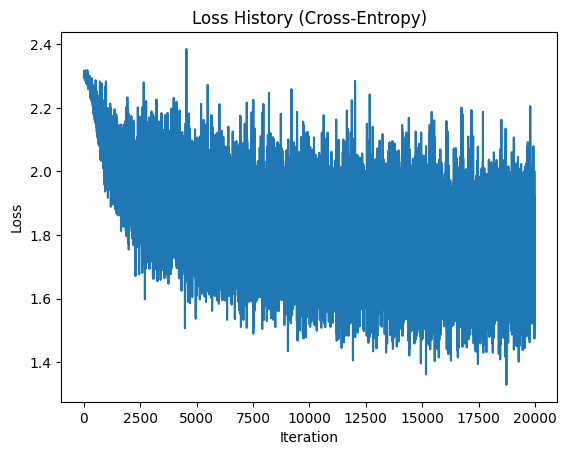

Training accuracy: 38.86%
Test accuracy: 38.62%


In [10]:
def softmax(z):
    z = z - z.max(dim=1, keepdim=True).values
    e = torch.exp(z)
    return e / e.sum(dim=1, keepdim=True)

# 3. Training loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        h, y_pred = forward(x_train)
        probs = softmax(y_pred)

        # Cross-entropy loss (+ L2 regularization)
        loss = -(1 / Ntr) * torch.sum(y_train_onehot * torch.log(probs + 1e-12)) \
               + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = (probs - y_train_onehot) / Ntr
        dw2 = h.t().mm(dy_pred) + reg * w2
        db2 = dy_pred.sum(dim=0)
        dh = dy_pred.mm(w2.t())
        dh_pre = dh * h * (1 - h)
        dw1 = x_train.t().mm(dh_pre) + reg * w1
        db1 = dh_pre.sum(dim=0)

        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    print(f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader)}")

    # Learning rate decay
    lr *= lr_decay

# 4. Plot loss history
plt.plot(loss_history)
plt.title("Loss History (Cross-Entropy)")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()


# 5/6. Accuracy
def accuracy(loader):
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            x = inputs.view(inputs.shape[0], -1)
            _, y_pred = forward(x)
            predicted = torch.argmax(y_pred, dim=1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total


print(f"Training accuracy: {accuracy(trainloader):.2f}%")
print(f"Test accuracy: {accuracy(testloader):.2f}%")

Cross-entropy started higher (2.205, close to the random-guess value ln 10 ~= 2.30) and fell to 1.746, so its values can’t be compared directly with the MSE losses in part (a). Accuracy was 38.86% on the training set and 38.62% on the test set, about 2.3 points below part (a). The tiny train/test gap (0.24) again points to underfitting. The slower start suggests the learning rate (1e-2) is conservative for cross-entropy, and a larger value would probably help. Since your repeated runs vary by a couple of points, treat the (a) vs (b) difference as roughly a tie rather than evidence that one loss is better.

Epoch 1/10, Loss: 2.2109706490039827
Epoch 2/10, Loss: 2.0217971885204316
Epoch 3/10, Loss: 1.9416033021211625
Epoch 4/10, Loss: 1.900292074084282
Epoch 5/10, Loss: 1.8711513379812241
Epoch 6/10, Loss: 1.8484531207084656
Epoch 7/10, Loss: 1.8300557316541672
Epoch 8/10, Loss: 1.8153080642223358
Epoch 9/10, Loss: 1.8032857484817504
Epoch 10/10, Loss: 1.7931743959188462


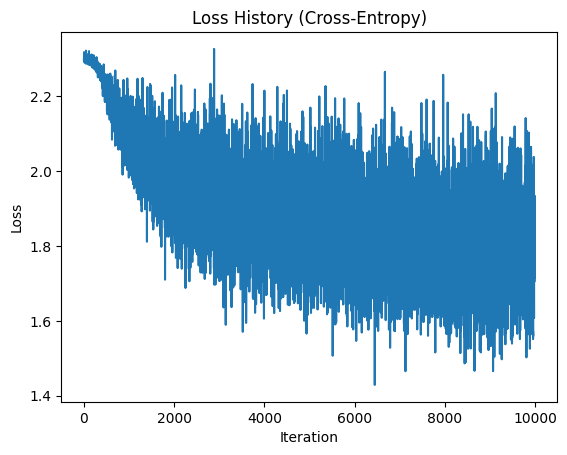

Training accuracy after 10 epochs: 37.22%
Test accuracy after 10 epochs: 37.19%


In [13]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# 1. Data loading
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 50
trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)
testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck')

# 2. Network parameters
Din = 3 * 32 * 32   # input size (flattened CIFAR-10 image)
H = 100             # hidden layer size
K = 10              # number of classes
std = 1e-2          # weight init std

w1 = torch.randn(Din, H) * std
b1 = torch.zeros(H)
w2 = torch.randn(H, K) * std
b2 = torch.zeros(K)

# Hyperparameters
iterations = 10     # part (c): 10 epochs
lr = 1e-2           # tune this (e.g. 1e-2, 1e-1)
lr_decay = 0.9
reg = 0

loss_history = []


def sigmoid(z):
    return 1.0 / (1.0 + torch.exp(-z))


def softmax(z):
    z = z - z.max(dim=1, keepdim=True).values   # numerical stability
    e = torch.exp(z)
    return e / e.sum(dim=1, keepdim=True)


def forward(x):
    h = sigmoid(x.mm(w1) + b1)   # hidden layer, sigmoid activation
    y = h.mm(w2) + b2            # output scores (logits)
    return h, y


# 3. Training loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        h, y_pred = forward(x_train)
        probs = softmax(y_pred)

        # Cross-entropy loss (+ L2 regularization)
        loss = -(1 / Ntr) * torch.sum(y_train_onehot * torch.log(probs + 1e-12)) \
               + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = (probs - y_train_onehot) / Ntr             # softmax + CE gradient
        dw2 = h.t().mm(dy_pred) + reg * w2                   # (H, K)
        db2 = dy_pred.sum(dim=0)                             # (K,)
        dh = dy_pred.mm(w2.t())                              # (Ntr, H)
        dh_pre = dh * h * (1 - h)                            # sigmoid derivative
        dw1 = x_train.t().mm(dh_pre) + reg * w1              # (Din, H)
        db1 = dh_pre.sum(dim=0)                              # (H,)

        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    print(f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader)}")

    # Learning rate decay
    lr *= lr_decay

# 4. Plot loss history
plt.plot(loss_history)
plt.title("Loss History (Cross-Entropy)")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()


# 5/6. Accuracy
def accuracy(loader):
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            x = inputs.view(inputs.shape[0], -1)
            _, y_pred = forward(x)
            predicted = torch.argmax(y_pred, dim=1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total


print(f"Training accuracy after {iterations} epochs: {accuracy(trainloader):.2f}%")
print(f"Test accuracy after {iterations} epochs: {accuracy(testloader):.2f}%")

After 10 epochs the loss reached 1.793, with 37.22% training and 37.19% test accuracy. This is about 1.6 points lower than the 20-epoch run in part (b) (38.86% train, 38.62% test), which is what you’d expect from half as many updates. The loss at epoch 10 here (1.793) almost matches part (b)’s loss at epoch 10 (1.794), so the 10-epoch run is essentially the first half of the 20-epoch run. The loss is still falling steadily at epoch 10 and the train/test gap is only 0.03 points, so the model is clearly underfitting rather than overfitting, and more epochs or a larger learning rate would raise accuracy. The learning-rate decay of 0.9 per epoch also shrinks the later updates, which is why the curve flattens.